In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
!pip install ultralytics opencv-python-headless shapely -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 4.3 MB/s eta 0:00:00


In [ ]:
import ultralytics, cv2
from ultralytics import YOLO

ultralytics.checks()

model = YOLO("yolov8n.pt")   # pretrained model auto-download hoga
print("Model loaded. Classes:", model.names[0])  # 'person' aana chahiye

Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 20.5/107.7 GB disk)
Model loaded. Classes: person


In [ ]:
from google.colab import files
uploaded = files.upload()   # Choose Files pe click karke video select karo

video_path = list(uploaded.keys())[0]
print("Video saved as:", video_path)

Saving 31372-360.mp4 to 31372-360.mp4
Video saved as: 31372-360.mp4


In [ ]:
import cv2

cap = cv2.VideoCapture(video_path)
fps    = cap.get(cv2.CAP_PROP_FPS)
width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Resolution: {width}x{height}, FPS: {fps}, Total frames: {frames}")

ret, frame = cap.read()
cv2.imwrite("first_frame.jpg", frame)   # Step 4 me isi frame pe zone banayenge
cap.release()

Resolution: 640x360, FPS: 24.0, Total frames: 515


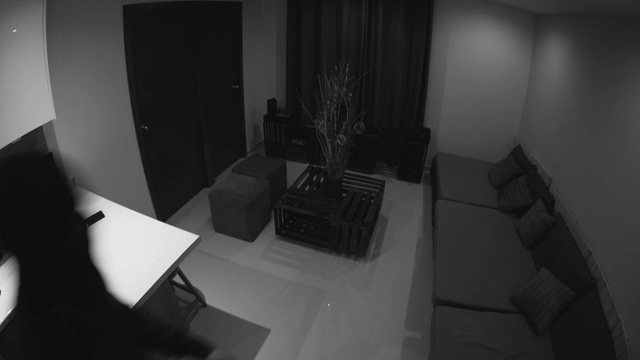

In [ ]:
from IPython.display import Image
Image("first_frame.jpg")


0: 384x640 (no detections), 357.7ms
Speed: 13.5ms preprocess, 357.7ms inference, 27.8ms postprocess per image at shape (1, 3, 384, 640)
Persons detected: 0


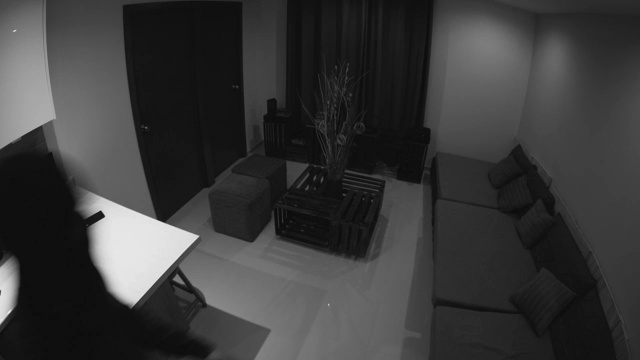

In [ ]:
from ultralytics import YOLO
import cv2
from IPython.display import Image

model = YOLO("yolov8n.pt")

frame = cv2.imread("first_frame.jpg")

# classes=[0] ka matlab sirf 'person' detect karo
results = model(frame, classes=[0], conf=0.4)

annotated = results[0].plot()
cv2.imwrite("detected_frame.jpg", annotated)

print("Persons detected:", len(results[0].boxes))
Image("detected_frame.jpg")

In [ ]:
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out = cv2.VideoWriter("step3_output.mp4", cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

frame_no = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    results = model(frame, classes=[0], conf=0.4, verbose=False)
    out.write(results[0].plot())
    frame_no += 1

cap.release()
out.release()
print("Done. Frames processed:", frame_no)

Done. Frames processed: 515


In [ ]:
from IPython.display import HTML
from base64 import b64encode
import os

# browser me chalne ke liye H.264 me convert
os.system("ffmpeg -y -i step3_output.mp4 -vcodec libx264 step3_final.mp4 -loglevel quiet")

mp4 = open("step3_final.mp4", "rb").read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f'<video width=640 controls><source src="{data_url}" type="video/mp4"></video>')

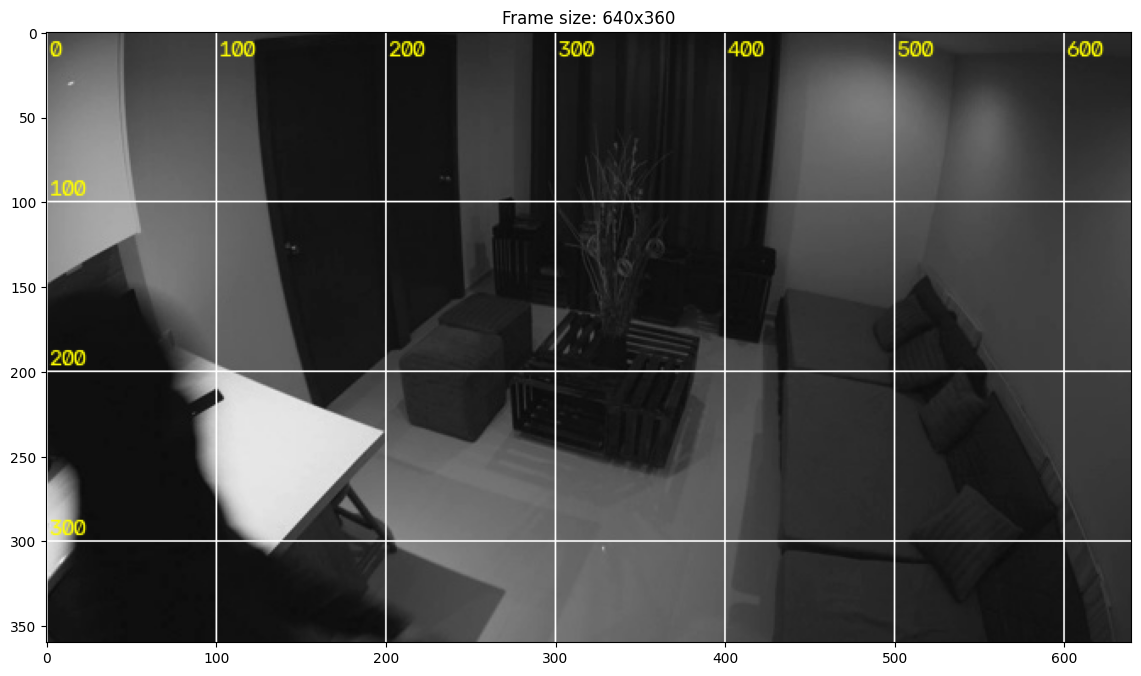

In [ ]:
import cv2
import matplotlib.pyplot as plt

frame = cv2.imread("first_frame.jpg")
h, w = frame.shape[:2]
grid = frame.copy()

step = 100   # har 100 pixel par line
for x in range(0, w, step):
    cv2.line(grid, (x, 0), (x, h), (255, 255, 255), 1)
    cv2.putText(grid, str(x), (x + 2, 15), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
for y in range(0, h, step):
    cv2.line(grid, (0, y), (w, y), (255, 255, 255), 1)
    cv2.putText(grid, str(y), (2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(grid, cv2.COLOR_BGR2RGB))
plt.title(f"Frame size: {w}x{h}")
plt.show()

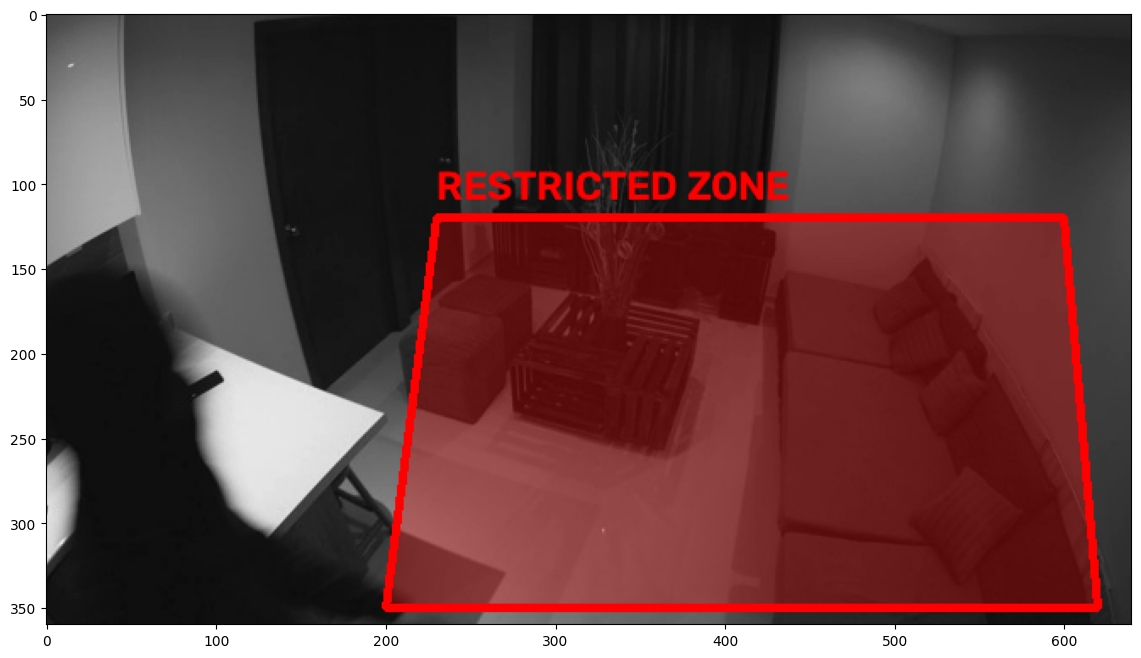

In [ ]:
# Frame 640x360 hai, to saare numbers isse andar hone chahiye
ZONE = [(230, 120), (600, 120), (620, 350), (200, 350)]   # TL, TR, BR, BL

preview = draw_zone(frame.copy(), ZONE)
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.show()

In [ ]:
import cv2, json
import numpy as np
from ultralytics import YOLO
from shapely.geometry import Point, Polygon

model = YOLO("yolov8n.pt")
CLASSES = [0, 1, 2, 3, 5, 7]   # person, bicycle, car, motorcycle, bus, truck

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Automatic zone (frame ke percentage me). Apne hisaab se badal sakte ho.
ZONE_PCT = [(0.55, 0.25), (0.95, 0.25), (0.95, 0.95), (0.55, 0.95)]
ZONE = [(int(x * w), int(y * h)) for x, y in ZONE_PCT]
zone_poly = Polygon(ZONE)
zone_pts = np.array(ZONE, np.int32)

out = cv2.VideoWriter("step5_output.mp4", cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

entered_ids = set()   # jo pehle hi zone me ghus chuke
events = []
frame_no = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break
    frame_no += 1

    # Zone ko halka laal rang do
    overlay = frame.copy()
    cv2.fillPoly(overlay, [zone_pts], (0, 0, 255))
    frame = cv2.addWeighted(overlay, 0.2, frame, 0.8, 0)
    cv2.polylines(frame, [zone_pts], True, (0, 0, 255), 2)
    cv2.putText(frame, "RESTRICTED ZONE", (ZONE[0][0], max(ZONE[0][1] - 8, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    results = model.track(frame, classes=CLASSES, conf=0.4, persist=True, verbose=False)
    boxes = results[0].boxes

    if boxes.id is not None:
        xyxy = boxes.xyxy.cpu().numpy()
        ids = boxes.id.int().cpu().tolist()
        clss = boxes.cls.int().cpu().tolist()

        for (x1, y1, x2, y2), tid, c in zip(xyxy, ids, clss):
            name = model.names[c]
            foot = Point((x1 + x2) / 2, y2)     # pair (neeche ka beech ka point)
            inside = zone_poly.contains(foot)

            color = (0, 0, 255) if inside else (0, 200, 0)
            label = f"{name} #{tid}" + (" INTRUSION" if inside else "")
            cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
            cv2.putText(frame, label, (int(x1), max(int(y1) - 6, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

            if inside and tid not in entered_ids:
                entered_ids.add(tid)
                events.append({
                    "object": name,
                    "track_id": tid,
                    "frame": frame_no,
                    "time_sec": round(frame_no / fps, 2)
                })

    out.write(frame)

cap.release()
out.release()

print("Frames processed:", frame_no)
print("Total intrusions:", len(events))
for e in events:
    print(e)

with open("intrusion_events.json", "w") as f:
    json.dump(events, f, indent=2)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 290ms
Prepared 1 package in 74ms
Installed 1 package in 0.98ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Frames processed: 515
Total intrusions: 0


In [ ]:
import os
from IPython.display import HTML
from base64 import b64encode

os.system("ffmpeg -y -i step5_output.mp4 -vcodec libx264 step5_final.mp4 -loglevel quiet")
mp4 = open("step5_final.mp4", "rb").read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f'<video width=640 controls><source src="{data_url}" type="video/mp4"></video>')

In [ ]:
import cv2, json
import numpy as np
from datetime import datetime, timedelta
from ultralytics import YOLO
from shapely.geometry import Point, Polygon

CLASSES = [0, 1, 2, 3, 5, 7]   # person, bicycle, car, motorcycle, bus, truck

# Off-hours: raat 22:00 (10 PM) se subah 06:00 (6 AM)
OFF_START = 22
OFF_END = 6

def is_off_hours(t):
    return t.hour >= OFF_START or t.hour < OFF_END

def run_geofence(video_path, zone_pct, sim_start="23:30:00",
                 out_name="step6_output.mp4", events_name="intrusion_events.json"):
    model = YOLO("yolov8s.pt")   # n se zyada accurate

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Zone bahar se aata hai (frontend se user ke clicks)
    ZONE = [(int(x * w), int(y * h)) for x, y in zone_pct]
    zone_poly = Polygon(ZONE)
    zone_pts = np.array(ZONE, np.int32)

    start_dt = datetime.strptime(sim_start, "%H:%M:%S")
    out = cv2.VideoWriter(out_name, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
    alerted_ids = set()
    events = []
    frame_no = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frame_no += 1

        now = start_dt + timedelta(seconds=frame_no / fps)
        off_hours = is_off_hours(now)

        # Pehle detection (clean frame par), phir drawing
        results = model.track(frame, classes=CLASSES, conf=0.25, persist=True, verbose=False)
        boxes = results[0].boxes

        overlay = frame.copy()
        cv2.fillPoly(overlay, [zone_pts], (0, 0, 255))
        frame = cv2.addWeighted(overlay, 0.2, frame, 0.8, 0)
        cv2.polylines(frame, [zone_pts], True, (0, 0, 255), 2)

        mode_text = "OFF-HOURS (ALERT ON)" if off_hours else "DAY TIME (ALERT OFF)"
        mode_color = (0, 0, 255) if off_hours else (0, 180, 0)
        cv2.putText(frame, f"{now.strftime('%H:%M:%S')}  |  {mode_text}", (10, 22),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, mode_color, 2)

        if boxes.id is not None:
            xyxy = boxes.xyxy.cpu().numpy()
            ids = boxes.id.int().cpu().tolist()
            clss = boxes.cls.int().cpu().tolist()

            for (x1, y1, x2, y2), tid, c in zip(xyxy, ids, clss):
                name = model.names[c]
                foot = Point((x1 + x2) / 2, y2)
                inside = zone_poly.contains(foot)

                if inside and off_hours:
                    color, label = (0, 0, 255), f"{name} #{tid} INTRUSION"
                    if tid not in alerted_ids:
                        alerted_ids.add(tid)
                        events.append({
                            "object": name,
                            "track_id": tid,
                            "frame": frame_no,
                            "video_time_sec": round(frame_no / fps, 2),
                            "simulated_clock": now.strftime("%H:%M:%S"),
                            "type": "INTRUSION_OFF_HOURS"
                        })
                elif inside:
                    color, label = (0, 215, 255), f"{name} #{tid} (allowed hours)"
                else:
                    color, label = (0, 200, 0), f"{name} #{tid}"

                cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
                cv2.putText(frame, label, (int(x1), max(int(y1) - 6, 12)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

        out.write(frame)

    cap.release()
    out.release()

    with open(events_name, "w") as f:
        json.dump(events, f, indent=2)

    print(f"[{sim_start}] Frames: {frame_no} | Intrusions: {len(events)}")
    for e in events:
        print(e)
    return events

In [ ]:
my_zone = [(0.55, 0.25), (0.95, 0.25), (0.95, 0.95), (0.55, 0.95)]

# Test A: raat 11:30 PM -> alert aana chahiye
run_geofence(video_path, my_zone, sim_start="23:30:00",
             out_name="night_output.mp4", events_name="events_night.json")

# Test B: dopahar 2:00 PM -> koi alert nahi
run_geofence(video_path, my_zone, sim_start="14:00:00",
             out_name="day_output.mp4", events_name="events_day.json")

[23:30:00] Frames: 515 | Intrusions: 3
{'object': 'person', 'track_id': 1, 'frame': 18, 'video_time_sec': 0.75, 'simulated_clock': '23:30:00', 'type': 'INTRUSION_OFF_HOURS'}
{'object': 'person', 'track_id': 3, 'frame': 74, 'video_time_sec': 3.08, 'simulated_clock': '23:30:03', 'type': 'INTRUSION_OFF_HOURS'}
{'object': 'person', 'track_id': 7, 'frame': 356, 'video_time_sec': 14.83, 'simulated_clock': '23:30:14', 'type': 'INTRUSION_OFF_HOURS'}
[14:00:00] Frames: 515 | Intrusions: 0


[]

In [ ]:
import os
from IPython.display import HTML, display
from base64 import b64encode

def show(name):
    os.system(f"ffmpeg -y -i {name}.mp4 -vcodec libx264 {name}_h264.mp4 -loglevel quiet")
    data = open(f"{name}_h264.mp4", "rb").read()
    url = "data:video/mp4;base64," + b64encode(data).decode()
    display(HTML(f'<p><b>{name}</b></p><video width=640 controls><source src="{url}" type="video/mp4"></video>'))

show("night_output")
show("day_output")

In [ ]:
import cv2, json, os

os.makedirs("evidence", exist_ok=True)

def save_evidence(video_file, events_file, pre_sec=2, post_sec=3):
    events = json.load(open(events_file))
    cap = cv2.VideoCapture(video_file)
    fps = cap.get(cv2.CAP_PROP_FPS)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    for e in events:
        f = e["frame"]
        base = e["object"] + "_id" + str(e["track_id"]) + "_f" + str(f)

        # 1. Screenshot
        cap.set(cv2.CAP_PROP_POS_FRAMES, f - 1)
        ret, img = cap.read()
        img_path = "evidence/" + base + ".jpg"
        if ret:
            cv2.imwrite(img_path, img)

        # 2. Clip
        start = max(0, f - int(pre_sec * fps))
        end = min(total, f + int(post_sec * fps))
        clip_path = "evidence/" + base + ".mp4"
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        out = cv2.VideoWriter(clip_path, fourcc, fps, (w, h))
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
        for _ in range(start, end):
            r, fr = cap.read()
            if not r:
                break
            out.write(fr)
        out.release()

        e["image"] = img_path
        e["clip"] = clip_path

    cap.release()
    return events

In [ ]:
events = save_evidence("night_output.mp4", "events_night.json")

for e in events:
    msg = (
        "INTRUSION ALERT\n"
        "Camera: cam_01\n"
        "Object: " + e["object"] + " (ID " + str(e["track_id"]) + ")\n"
        "Time: " + e["simulated_clock"] + "\n"
        "Evidence: " + e["image"]
    )
    print(msg)
    print("-" * 30)

with open("alerts_final.json", "w") as f:
    json.dump(events, f, indent=2)

print("Total alerts:", len(events))

INTRUSION ALERT
Camera: cam_01
Object: person (ID 1)
Time: 23:30:00
Evidence: evidence/person_id1_f18.jpg
------------------------------
INTRUSION ALERT
Camera: cam_01
Object: person (ID 3)
Time: 23:30:03
Evidence: evidence/person_id3_f74.jpg
------------------------------
INTRUSION ALERT
Camera: cam_01
Object: person (ID 7)
Time: 23:30:14
Evidence: evidence/person_id7_f356.jpg
------------------------------
Total alerts: 3


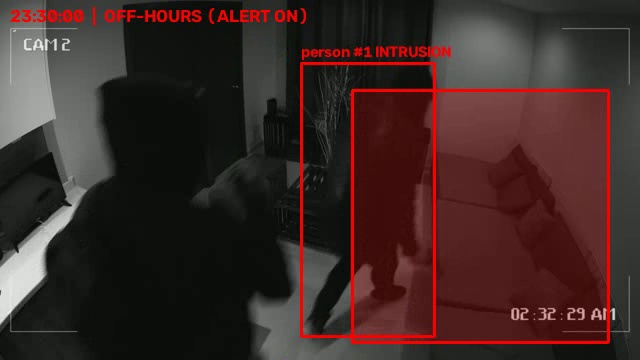

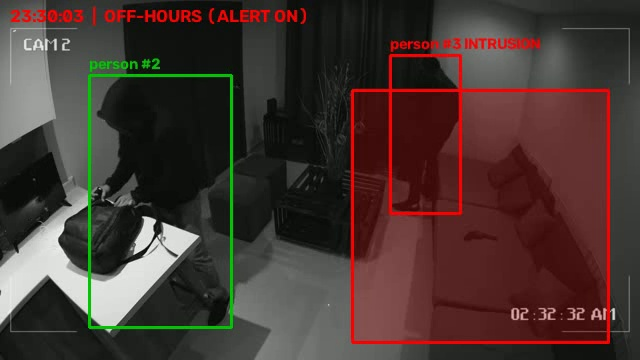

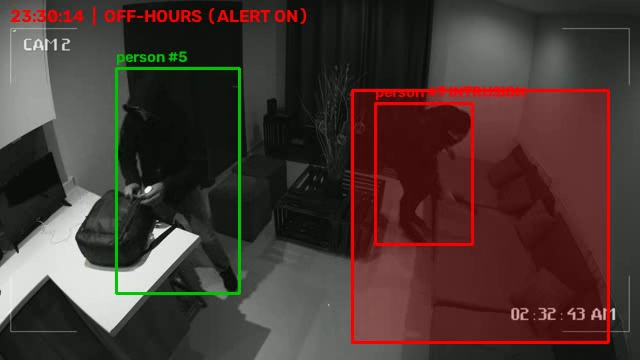

In [ ]:
from IPython.display import Image, display

for e in events:
    display(Image(e["image"]))

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("evidence_pack", "zip", "evidence")
files.download("evidence_pack.zip")
files.download("alerts_final.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
from datetime import datetime

CAMERA_ID = "cam_01"
ZONE_NAME = "restricted_zone_1"

events = json.load(open("alerts_final.json"))

clean = []
for i, e in enumerate(events, start=1):
    clean.append({
        "alert_id": "ALT-" + datetime.now().strftime("%Y%m%d") + "-" + str(i).zfill(3),
        "camera_id": CAMERA_ID,
        "zone": ZONE_NAME,
        "event_type": e["type"],
        "object_class": e["object"],
        "track_id": e["track_id"],
        "timestamp": e["simulated_clock"],
        "video_time_sec": e["video_time_sec"],
        "severity": "HIGH" if e["object"] == "person" else "MEDIUM",
        "image_path": e["image"],
        "clip_path": e["clip"],
        "status": "NEW"
    })

with open("alerts_backend.json", "w") as f:
    json.dump(clean, f, indent=2)

print("Total alerts:", len(clean))
print(json.dumps(clean[0], indent=2) if clean else "Koi alert nahi")

from google.colab import files
files.download("alerts_backend.json")

Total alerts: 3
{
  "alert_id": "ALT-20261016-001",
  "camera_id": "cam_01",
  "zone": "restricted_zone_1",
  "event_type": "INTRUSION_OFF_HOURS",
  "object_class": "person",
  "track_id": 1,
  "timestamp": "23:30:00",
  "video_time_sec": 0.75,
  "severity": "HIGH",
  "image_path": "evidence/person_id1_f18.jpg",
  "clip_path": "evidence/person_id1_f18.mp4",
  "status": "NEW"
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import smtplib, json, os
from email.message import EmailMessage

SENDER = "rawatsandhya104@gmail.com"
APP_PASSWORD = "gvzw zvfs jqem evzs"
RECEIVER = "pr481068@gmail.com"


def send_email(alert):
    msg = EmailMessage()
    msg["Subject"] = "INTRUSION ALERT: " + alert["object_class"] + " at " + alert["timestamp"]
    msg["From"] = SENDER
    msg["To"] = RECEIVER

    body = (
        "INTRUSION ALERT\n"
        "Camera: " + alert["camera_id"] + "\n"
        "Zone: " + alert["zone"] + "\n"
        "Object: " + alert["object_class"] + " (ID " + str(alert["track_id"]) + ")\n"
        "Time: " + alert["timestamp"] + "\n"
        "Severity: " + alert["severity"]
    )
    msg.set_content(body)

    if os.path.exists(alert["image_path"]):
        with open(alert["image_path"], "rb") as f:
            msg.add_attachment(f.read(), maintype="image",
                               subtype="jpeg", filename="screenshot.jpg")
    else:
        print("Screenshot nahi mila:", alert["image_path"])

    with smtplib.SMTP_SSL("smtp.gmail.com", 465) as server:
        server.login(SENDER, APP_PASSWORD)
        server.send_message(msg)
    print("Email sent:", alert["alert_id"])


alerts = json.load(open("alerts_backend.json"))
print("Alerts in file:", len(alerts))

for a in alerts:
    send_email(a)

print("Total emails:", len(alerts))

Alerts in file: 3
Email sent: ALT-20261016-001
Email sent: ALT-20261016-002
Email sent: ALT-20261016-003
Total emails: 3


In [ ]:
alerts = json.load(open("alerts_backend.json"))

for a in alerts:
    send_email(a)

print("Total emails:", len(alerts))

Email sent: ALT-20261016-001
Email sent: ALT-20261016-002
Email sent: ALT-20261016-003
Total emails: 3


In [ ]:
from google.colab import files
up = files.upload()
VIDEO_NAME = list(up.keys())[0]
print("Video ready:", VIDEO_NAME)

Saving 31372-360.mp4 to 31372-360 (1).mp4
Video ready: 31372-360 (1).mp4


In [ ]:
import cv2, json, os, smtplib
import numpy as np
from datetime import datetime, timedelta
from email.message import EmailMessage
from ultralytics import YOLO
from shapely.geometry import Point, Polygon

# ---------- SETTINGS (sirf yahan badlo) ----------
VIDEO_PATH = VIDEO_NAME
SIM_START = "23:30:00"
CAMERA_ID = "cam_01"
ZONE_NAME = "restricted_zone_1"
ZONE_PCT = [(0.55, 0.25), (0.95, 0.25), (0.95, 0.95), (0.55, 0.95)]
OFF_START, OFF_END = 22, 6
CLASSES = [0, 1, 2, 3, 5, 7]
SEND_EMAIL = True

SENDER = "rawatsandhya104@gmail.com"
RECEIVER = "pr481068@gmail.com"
APP_PASSWORD = os.environ.get("GMAIL_APP_PASSWORD", "")

RED, GREEN, YELLOW = (0, 0, 255), (0, 200, 0), (0, 215, 255)
os.makedirs("evidence", exist_ok=True)


def is_off_hours(t):
    return t.hour >= OFF_START or t.hour < OFF_END


def detect(video_path, out_name="output.mp4"):
    model = YOLO("yolov8s.pt")
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    zone = [(int(x * w), int(y * h)) for x, y in ZONE_PCT]
    poly = Polygon(zone)
    pts = np.array(zone, np.int32)
    start_dt = datetime.strptime(SIM_START, "%H:%M:%S")
    out = cv2.VideoWriter(out_name, cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))
    alerted, events, n = set(), [], 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        n += 1
        now = start_dt + timedelta(seconds=n / fps)
        off = is_off_hours(now)

        res = model.track(frame, classes=CLASSES, conf=0.25,
                          persist=True, verbose=False)
        boxes = res[0].boxes

        ov = frame.copy()
        cv2.fillPoly(ov, [pts], RED)
        frame = cv2.addWeighted(ov, 0.2, frame, 0.8, 0)
        cv2.polylines(frame, [pts], True, RED, 2)
        mode = "OFF-HOURS (ALERT ON)" if off else "DAY TIME (ALERT OFF)"
        cv2.putText(frame, now.strftime("%H:%M:%S") + " | " + mode,
                    (10, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                    RED if off else GREEN, 2)

        if boxes.id is not None:
            xyxy = boxes.xyxy.cpu().numpy()
            ids = boxes.id.int().cpu().tolist()
            clss = boxes.cls.int().cpu().tolist()
            for (x1, y1, x2, y2), tid, c in zip(xyxy, ids, clss):
                name = model.names[c]
                inside = poly.contains(Point((x1 + x2) / 2, y2))
                if inside and off:
                    color, label = RED, name + " #" + str(tid) + " INTRUSION"
                    if tid not in alerted:
                        alerted.add(tid)
                        events.append({
                            "object": name, "track_id": tid, "frame": n,
                            "video_time_sec": round(n / fps, 2),
                            "clock": now.strftime("%H:%M:%S")})
                elif inside:
                    color, label = YELLOW, name + " #" + str(tid) + " (allowed)"
                else:
                    color, label = GREEN, name + " #" + str(tid)
                cv2.rectangle(frame, (int(x1), int(y1)),
                              (int(x2), int(y2)), color, 2)
                cv2.putText(frame, label, (int(x1), max(int(y1) - 6, 12)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
        out.write(frame)

    cap.release()
    out.release()
    print("Frames:", n, "| Intrusions:", len(events))
    return events


def save_evidence(video_file, events, pre=2, post=3):
    cap = cv2.VideoCapture(video_file)
    fps = cap.get(cv2.CAP_PROP_FPS)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    for e in events:
        f = e["frame"]
        base = e["object"] + "_id" + str(e["track_id"]) + "_f" + str(f)
        cap.set(cv2.CAP_PROP_POS_FRAMES, f - 1)
        ok, img = cap.read()
        e["image"] = "evidence/" + base + ".jpg"
        if ok:
            cv2.imwrite(e["image"], img)

        start = max(0, f - int(pre * fps))
        end = min(total, f + int(post * fps))
        e["clip"] = "evidence/" + base + ".mp4"
        wr = cv2.VideoWriter(e["clip"], cv2.VideoWriter_fourcc(*"mp4v"),
                             fps, (w, h))
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
        for _ in range(start, end):
            ok, fr = cap.read()
            if not ok:
                break
            wr.write(fr)
        wr.release()
    cap.release()
    return events


def build_alerts(events):
    day = datetime.now().strftime("%Y%m%d")
    alerts = []
    for i, e in enumerate(events, start=1):
        alerts.append({
            "alert_id": "ALT-" + day + "-" + str(i).zfill(3),
            "camera_id": CAMERA_ID,
            "zone": ZONE_NAME,
            "event_type": "INTRUSION_OFF_HOURS",
            "object_class": e["object"],
            "track_id": e["track_id"],
            "timestamp": e["clock"],
            "video_time_sec": e["video_time_sec"],
            "severity": "HIGH" if e["object"] == "person" else "MEDIUM",
            "image_path": e["image"],
            "clip_path": e["clip"],
            "status": "NEW"})
    return alerts


def send_email(a):
    msg = EmailMessage()
    msg["Subject"] = "INTRUSION ALERT: " + a["object_class"] + " at " + a["timestamp"]
    msg["From"], msg["To"] = SENDER, RECEIVER
    msg.set_content(
        "Camera: " + a["camera_id"] + "\nZone: " + a["zone"] +
        "\nObject: " + a["object_class"] + " (ID " + str(a["track_id"]) + ")" +
        "\nTime: " + a["timestamp"] + "\nSeverity: " + a["severity"])
    with open(a["image_path"], "rb") as f:
        msg.add_attachment(f.read(), maintype="image",
                           subtype="jpeg", filename="screenshot.jpg")
    with smtplib.SMTP_SSL("smtp.gmail.com", 465) as s:
        s.login(SENDER, APP_PASSWORD)
        s.send_message(msg)
    print("Email sent:", a["alert_id"])


if __name__ == "__main__":
    events = detect(VIDEO_PATH)
    events = save_evidence("output.mp4", events)
    alerts = build_alerts(events)
    with open("alerts_backend.json", "w") as f:
        json.dump(alerts, f, indent=2)
    print("Alerts saved:", len(alerts))

    if SEND_EMAIL and APP_PASSWORD:
        for a in alerts:
            send_email(a)
    else:
        print("Email skip (password set nahi hai)")

Frames: 515 | Intrusions: 3
Alerts saved: 3
Email sent: ALT-20261016-001
Email sent: ALT-20261016-002
Email sent: ALT-20261016-003


In [ ]:
import shutil
from google.colab import files

shutil.copy("output.mp4", "evidence/output_full.mp4")
shutil.make_archive("final_project_output", "zip", "evidence")
files.download("final_project_output.zip")
files.download("alerts_backend.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.listdir())

['.config', 'first_frame.jpg', 'day_output_h264.mp4', 'step5_final.mp4', 'zone_config.json', 'final_project_output.zip', 'detected_frame.jpg', 'yolov8n.pt', 'events_day.json', 'alerts_final.json', 'alerts_backend.json', 'step5_output.mp4', 'events_night.json', 'yolov8s.pt', 'evidence_pack.zip', 'step3_final.mp4', '31372-360.mp4', '31372-360 (1).mp4', 'day_output.mp4', 'intrusion_events.json', 'step3_output.mp4', 'night_output.mp4', 'evidence', 'output.mp4', 'night_output_h264.mp4']
